# 07 · Senescence scores per cell (SenePy and SenMayo) — GSE216146

Do chemotherapy (cisplatin) brains contain more senescent-like cells, and in which cell types?

Three per-cell scores, each computed **within each cell type separately** (so a score compares cells of the same
type; values are not comparable across cell types):
1. **SenePy universal** (Sanborn et al., `senepy` 1.0.1): all 43 mouse cell-type senescence signatures from Tabula
   Muris Senis merged with SenePy's permutation threshold (genes recurring in more signatures than expected by chance).
   Needed because SenePy has only one brain signature (microglia).
2. **SenePy matched**, only where a matching signature exists (`senescence.matched`): microglia (brain microglia),
   endothelial, BAM (macrophages), mural/fibroblast.
3. **SenMayo** (Saul et al. 2022; `resources/SAUL_SEN_MAYO.mouse.gmt`): `sc.tl.score_genes`.

Hemoglobin and mitochondrial genes, and `annotation.ambient_genes`, are removed from the SenePy signatures (the
universal signature is otherwise led by hemoglobins, i.e. blood contamination in the atlas).

**Statistics:** the replicate is the sample. Per biosample x cell type: mean score and fraction of "high-score" cells
(above the `high_quantile` of control cells of that type); then OLS `~ batch + condition` per cell type
(n = 3 vs 3, exploratory).

**Input:** `results/03_annotated.h5ad` · **Output:** `results/07_senescence_scores.tsv.gz` (per-cell scores),
tables `results/tables/07_*`, plots `results/plots/07_*`.

In [1]:
import gc
import sys
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

with warnings.catch_warnings():   # senepy imports the deprecated pkg_resources (env pins setuptools<81)
    warnings.simplefilter("ignore", UserWarning)
    import senepy

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import sc_utils as scu

cfg = scu.load_config(ROOT / "config.yaml")
p = cfg["senescence"]
scu.setup_plotting()
pd.set_option("display.max_rows", 200)
print("senepy", version("senepy"), "| scanpy", version("scanpy"))
p

senepy 1.0.1 | scanpy 1.12.5


{'senmayo_gmt': 'resources/SAUL_SEN_MAYO.mouse.gmt',
 'senepy_species': 'Mouse',
 'matched': {'Microglia': '^microglial cell$',
  'Endothelial': 'endothelial|endocardial',
  'BAM': 'macrophage|Kupffer',
  'Mural/Fibroblast': '^(?:fibroblast|smooth muscle cell)$'},
 'matched_overlap': 2,
 'exclude_gene_regex': '^(Hb[ab]-|mt-)',
 'min_cells_per_sample': 10,
 'formula': '~ batch + condition',
 'high_quantile': 0.95,
 'fdr': 0.1}

In [2]:
adata = sc.read_h5ad(cfg["paths"]["results_dir"] / "03_annotated.h5ad")
drop = cfg["downstream"]["exclude_cell_types"]
adata = adata[~adata.obs["cell_type"].isin(drop)].copy()
adata.obs["cell_type"] = adata.obs["cell_type"].cat.remove_unused_categories()
del adata.layers["counts"], adata.obsp
gc.collect()
adata

AnnData object with n_obs × n_vars = 9728 × 19941
    obs: 'biosample', 'pathology', 'batch', 'doublet_score', 'predicted_doublet', 'MajorCellType', 'orig_celltype', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'condition', 'leiden_res_0.15', 'leiden_res_0.50', 'leiden_res_2.00', 'ct_label', 'ct_majority', 'ct_conf', 'ct_class', 'ct_majority_class', 'cell_type', 'cell_type_fine'
    var: 'mt', 'ribo', 'hb', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'MajorCellType_colors', 'batch_colors', 'biosample_colors', 'cell_type_colors', 'cell_type_fine_colors', 'condition_colors', 'ct_class_colors', 'hvg', 'leiden_res_0.15', 'leiden_res_0.15_colors', 'leiden_res_0.50', 'leiden_res_0.50_colors', 'leiden_res_2.00', 'leiden_res_2.00_colors', 'log1p', 'neighbors', 'pca', 'qc_colors', 'umap'
    obsm

## 1. Signatures

In [3]:
sigs, matched = scu.senepy_signatures(cfg, adata.obs["cell_type"].cat.categories)
senmayo = next(iter(scu.read_gmt(ROOT / p["senmayo_gmt"]).values()))
in_data = lambda genes: sum(g in adata.var_names for g in genes)
pd.DataFrame({"genes": {k: len(v) for k, v in sigs.items()} | {"SenMayo": len(senmayo)},
              "in_data": {k: in_data([g for g, _ in v]) for k, v in sigs.items()} | {"SenMayo": in_data(senmayo)}})

,genes,in_data
universal,1155,893
matched_Microglia,96,48
matched_Endothelial,110,83
matched_BAM,825,697
matched_Mural_Fibroblast,355,268
SenMayo,117,101


## 2. Per-cell scores (within each cell type)

In [4]:
scores = pd.DataFrame(index=adata.obs_names, columns=["senepy_universal", "senepy_matched", "senmayo"], dtype=float)
senmayo_in = [g for g in senmayo if g in adata.var_names]
for ct in adata.obs["cell_type"].cat.categories:
    sub = adata[adata.obs["cell_type"] == ct].copy()
    scores.loc[sub.obs_names, "senepy_universal"] = senepy.score_hub(sub, sigs["universal"], verbose=False)
    if ct in matched:
        scores.loc[sub.obs_names, "senepy_matched"] = senepy.score_hub(sub, sigs[matched[ct]], verbose=False)
    sc.tl.score_genes(sub, senmayo_in, ctrl_size=50, random_state=0, score_name="s")
    scores.loc[sub.obs_names, "senmayo"] = sub.obs["s"].to_numpy()
    del sub
gc.collect()

score_cols = list(scores.columns)
adata.obs[score_cols] = scores
# z-score within cell type, for plotting all cells on one UMAP
for col in score_cols:
    g = adata.obs.groupby("cell_type", observed=True)[col]
    adata.obs[f"{col}_z"] = (adata.obs[col] - g.transform("mean")) / g.transform("std")

out = adata.obs[["biosample", "condition", "batch", "cell_type", "cell_type_fine"] + score_cols]
out.to_csv(cfg["paths"]["results_dir"] / "07_senescence_scores.tsv.gz", sep="\t")
out[score_cols].describe().round(3)

,senepy_universal,senepy_matched,senmayo
count,9728.000,3622.000,9728.000
mean,0.162,-0.012,0.042
std,0.158,0.032,0.104
min,-0.059,-0.170,-0.185
25%,0.045,-0.024,-0.035
50%,0.095,-0.013,0.007
75%,0.277,-0.001,0.109
max,0.893,0.207,0.469


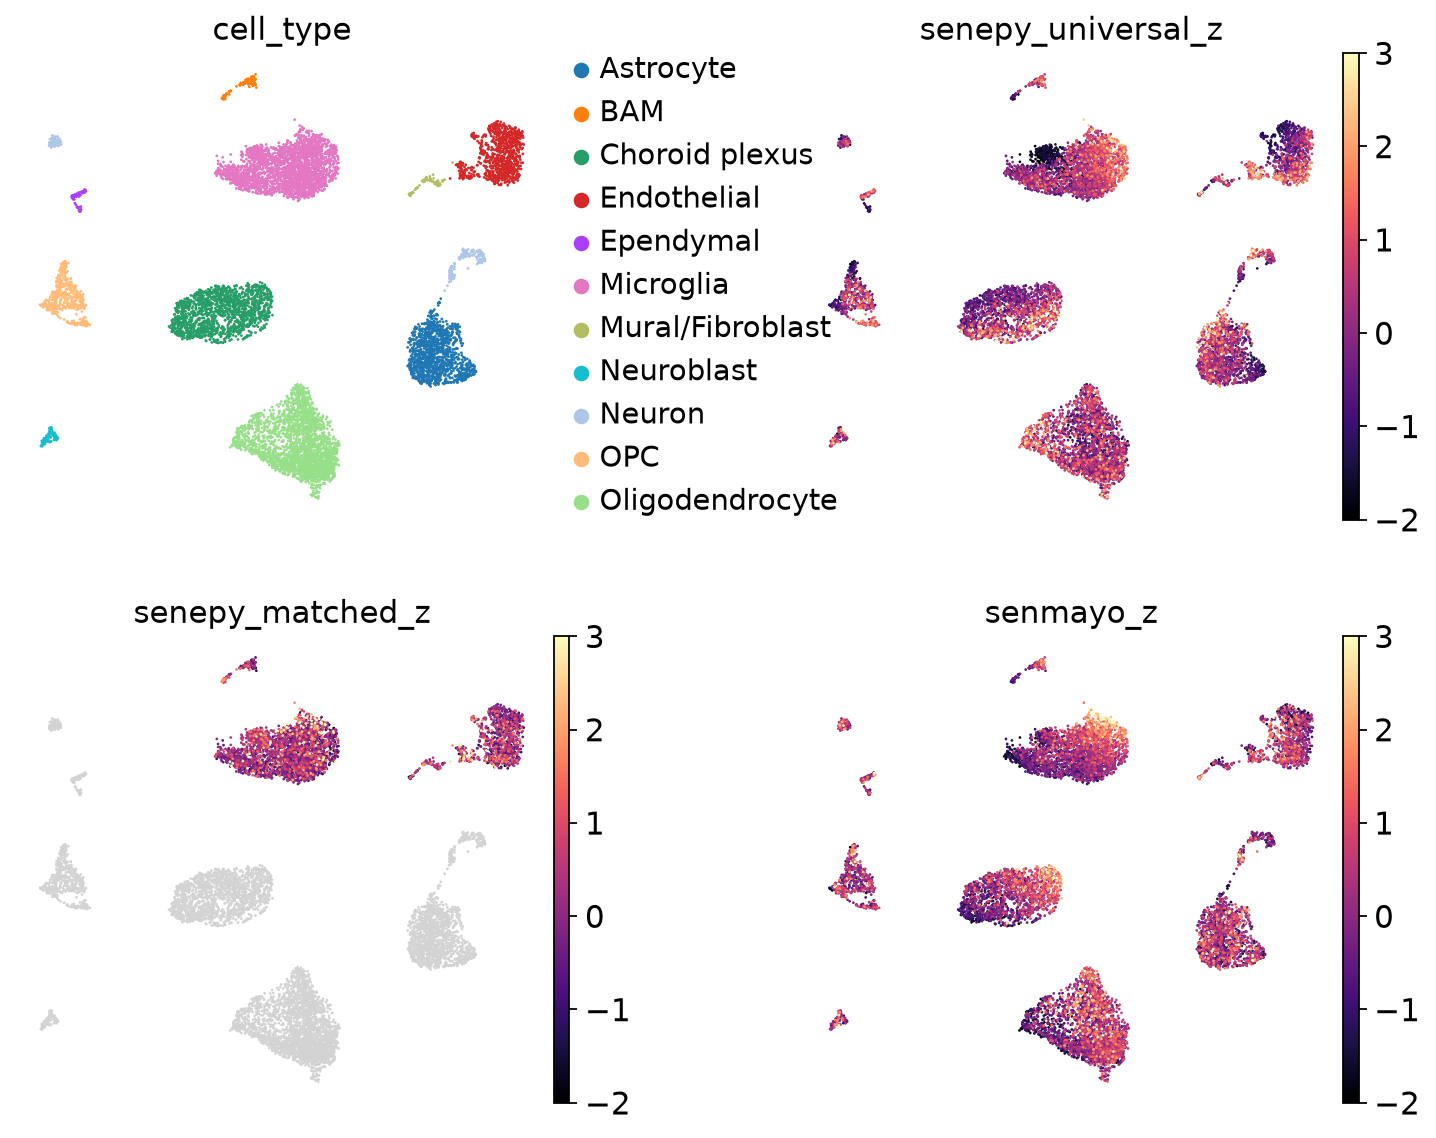

In [5]:
fig = sc.pl.umap(adata, color=["cell_type"] + [f"{c}_z" for c in score_cols], ncols=2, wspace=0.35, size=6,
                 cmap="magma", vmin=-2, vmax=3, return_fig=True)
scu.save_fig(fig, cfg, "07_umap_scores")
plt.show()

In [6]:
# Agreement between scores (Spearman, per cell type)
corr = (adata.obs.groupby("cell_type", observed=True)[score_cols]
        .apply(lambda d: pd.Series({"universal_vs_senmayo": d["senepy_universal"].corr(d["senmayo"], method="spearman"),
                                    "matched_vs_senmayo": d["senepy_matched"].corr(d["senmayo"], method="spearman"),
                                    "universal_vs_matched": d["senepy_universal"].corr(d["senepy_matched"], method="spearman")})))
corr.round(2)

,universal_vs_senmayo,matched_vs_senmayo,universal_vs_matched
cell_type,,,
Astrocyte,0.15,NaN,NaN
BAM,0.54,-0.53,-0.68
Choroid plexus,0.12,NaN,NaN
Endothelial,0.01,0.11,0.09
Ependymal,-0.01,NaN,NaN
Microglia,0.40,0.02,-0.26
Mural/Fibroblast,-0.08,-0.22,-0.23
Neuroblast,-0.14,NaN,NaN
Neuron,-0.25,NaN,NaN


## 3. Sample-level test

For every score and cell type: (a) mean score per sample, (b) fraction of high-score cells per sample (threshold =
`high_quantile` of the control cells of that type). OLS `~ batch + condition` across the samples with
>= `min_cells_per_sample` cells of that type.

In [7]:
obs = adata.obs
meta = (obs[["biosample", "condition", "batch"]].drop_duplicates().set_index("biosample").sort_values(["condition", "batch"]))
meta.index = meta.index.astype(str)
meta["condition"] = meta["condition"].cat.remove_unused_categories()
meta["batch"] = meta["batch"].astype(str)
ref = meta["condition"].cat.categories[0]

n = obs.groupby(["biosample", "cell_type"], observed=True).size()
ok = n[n >= p["min_cells_per_sample"]].index

tests, per_sample = [], {}
for col in score_cols:
    sub = obs.dropna(subset=[col])
    thr = sub[sub["condition"] == ref].groupby("cell_type", observed=True)[col].quantile(p["high_quantile"])
    sub = sub.assign(high=sub[col] > sub["cell_type"].map(thr).astype(float))
    for stat, agg in [("mean", sub.groupby(["biosample", "cell_type"], observed=True)[col].mean()),
                      ("frac_high", sub.groupby(["biosample", "cell_type"], observed=True)["high"].mean())]:
        agg = agg[agg.index.isin(ok)]
        wide = agg.unstack("cell_type")
        wide.index = wide.index.astype(str)
        per_sample[(col, stat)] = wide
        r = scu.ols_by_column(wide, meta, p["formula"])
        r.index.name = "cell_type"
        tests.append(r.assign(score=col, statistic=stat).reset_index())
tests = pd.concat(tests, ignore_index=True)
tests["fdr"] = tests.groupby(["score", "statistic"])["pval"].transform(scu.bh_fdr)
tests = tests.sort_values("pval")
tests.to_csv(cfg["paths"]["tables_dir"] / "07_senescence_tests.tsv", sep="\t", index=False)
tests[["score", "statistic", "cell_type", f"mean_{ref}", "mean_Chemotherapy", "coef", "pval", "fdr", "n_samples"]].round(4).head(25)

,score,statistic,cell_type,mean_Control,mean_Chemotherapy,coef,pval,fdr,n_samples
44,senmayo,frac_high,Endothelial,0.0495,0.1353,0.0858,0.0141,0.1131,6
2,senepy_universal,mean,Choroid plexus,0.0184,0.0289,0.0106,0.0226,0.1804,6
16,senepy_universal,frac_high,Microglia,0.0666,0.1439,0.0772,0.0259,0.2073,6
33,senmayo,mean,Endothelial,0.0653,0.0778,0.0125,0.0270,0.1600,6
40,senmayo,mean,Oligodendrocyte,-0.0368,-0.0292,0.0077,0.0400,0.1600,6
42,senmayo,frac_high,BAM,0.0635,0.0317,-0.0635,0.0422,0.1687,5
5,senepy_universal,mean,Microglia,0.3358,0.3704,0.0346,0.0604,0.2415,6
51,senmayo,frac_high,Oligodendrocyte,0.0568,0.1042,0.0474,0.1104,0.2944,6
26,senepy_matched,frac_high,BAM,0.0692,0.1762,0.1474,0.1287,0.3587,5
50,senmayo,frac_high,OPC,0.0625,0.0300,-0.0325,0.2358,0.4716,6


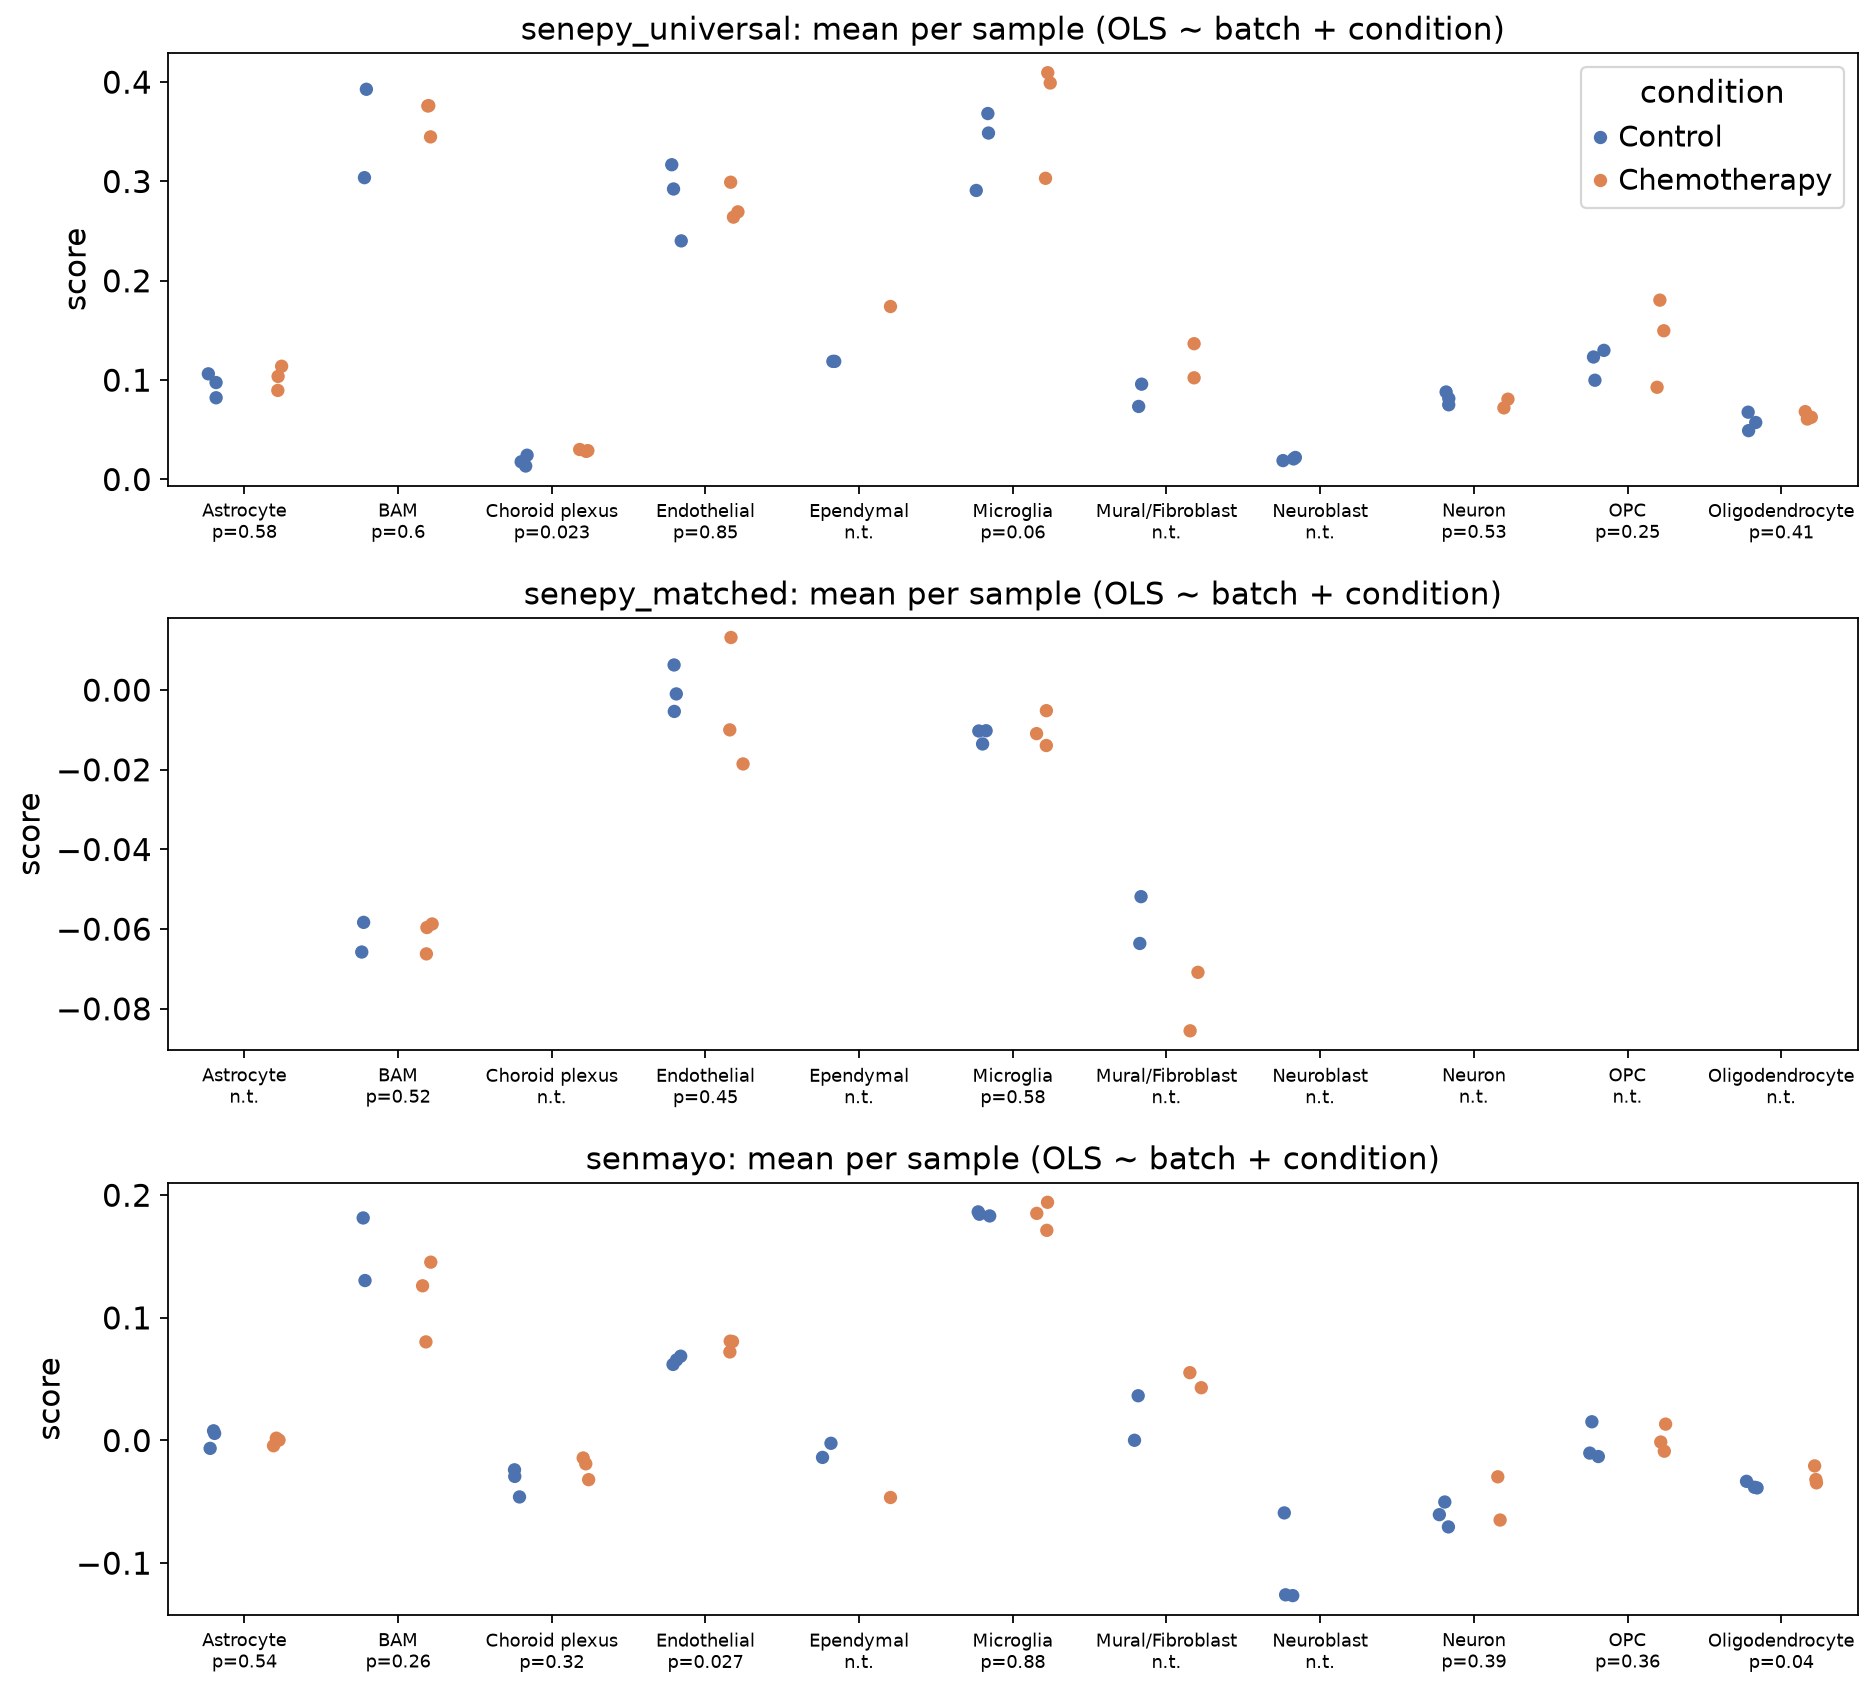

In [8]:
# Mean score per sample: one panel per score, cell types on x, samples as points coloured by condition
fig, axes = plt.subplots(len(score_cols), 1, figsize=(12, 3.6 * len(score_cols)))
for ax, col in zip(axes, score_cols):
    long = (per_sample[(col, "mean")].stack().rename("score").reset_index()
            .merge(meta, left_on="biosample", right_index=True))
    sns.stripplot(long, x="cell_type", y="score", hue="condition", dodge=True, size=6, ax=ax,
                  palette={"Control": "#4c72b0", "Chemotherapy": "#dd8452"}, legend=ax is axes[0])
    t = tests[(tests["score"] == col) & (tests["statistic"] == "mean")].set_index("cell_type")
    pv = t["pval"].reindex([c.get_text() for c in ax.get_xticklabels()])
    labels = [f"{ct}\n{'n.t.' if np.isnan(v) else f'p={v:.2g}'}" for ct, v in pv.items()]
    ax.set_xticks(ax.get_xticks(), labels, fontsize=8)
    ax.set_title(f"{col}: mean per sample (OLS ~ batch + condition)"); ax.set_xlabel(""); ax.grid(False)
fig.tight_layout()
scu.save_fig(fig, cfg, "07_scores_per_sample")
plt.show()

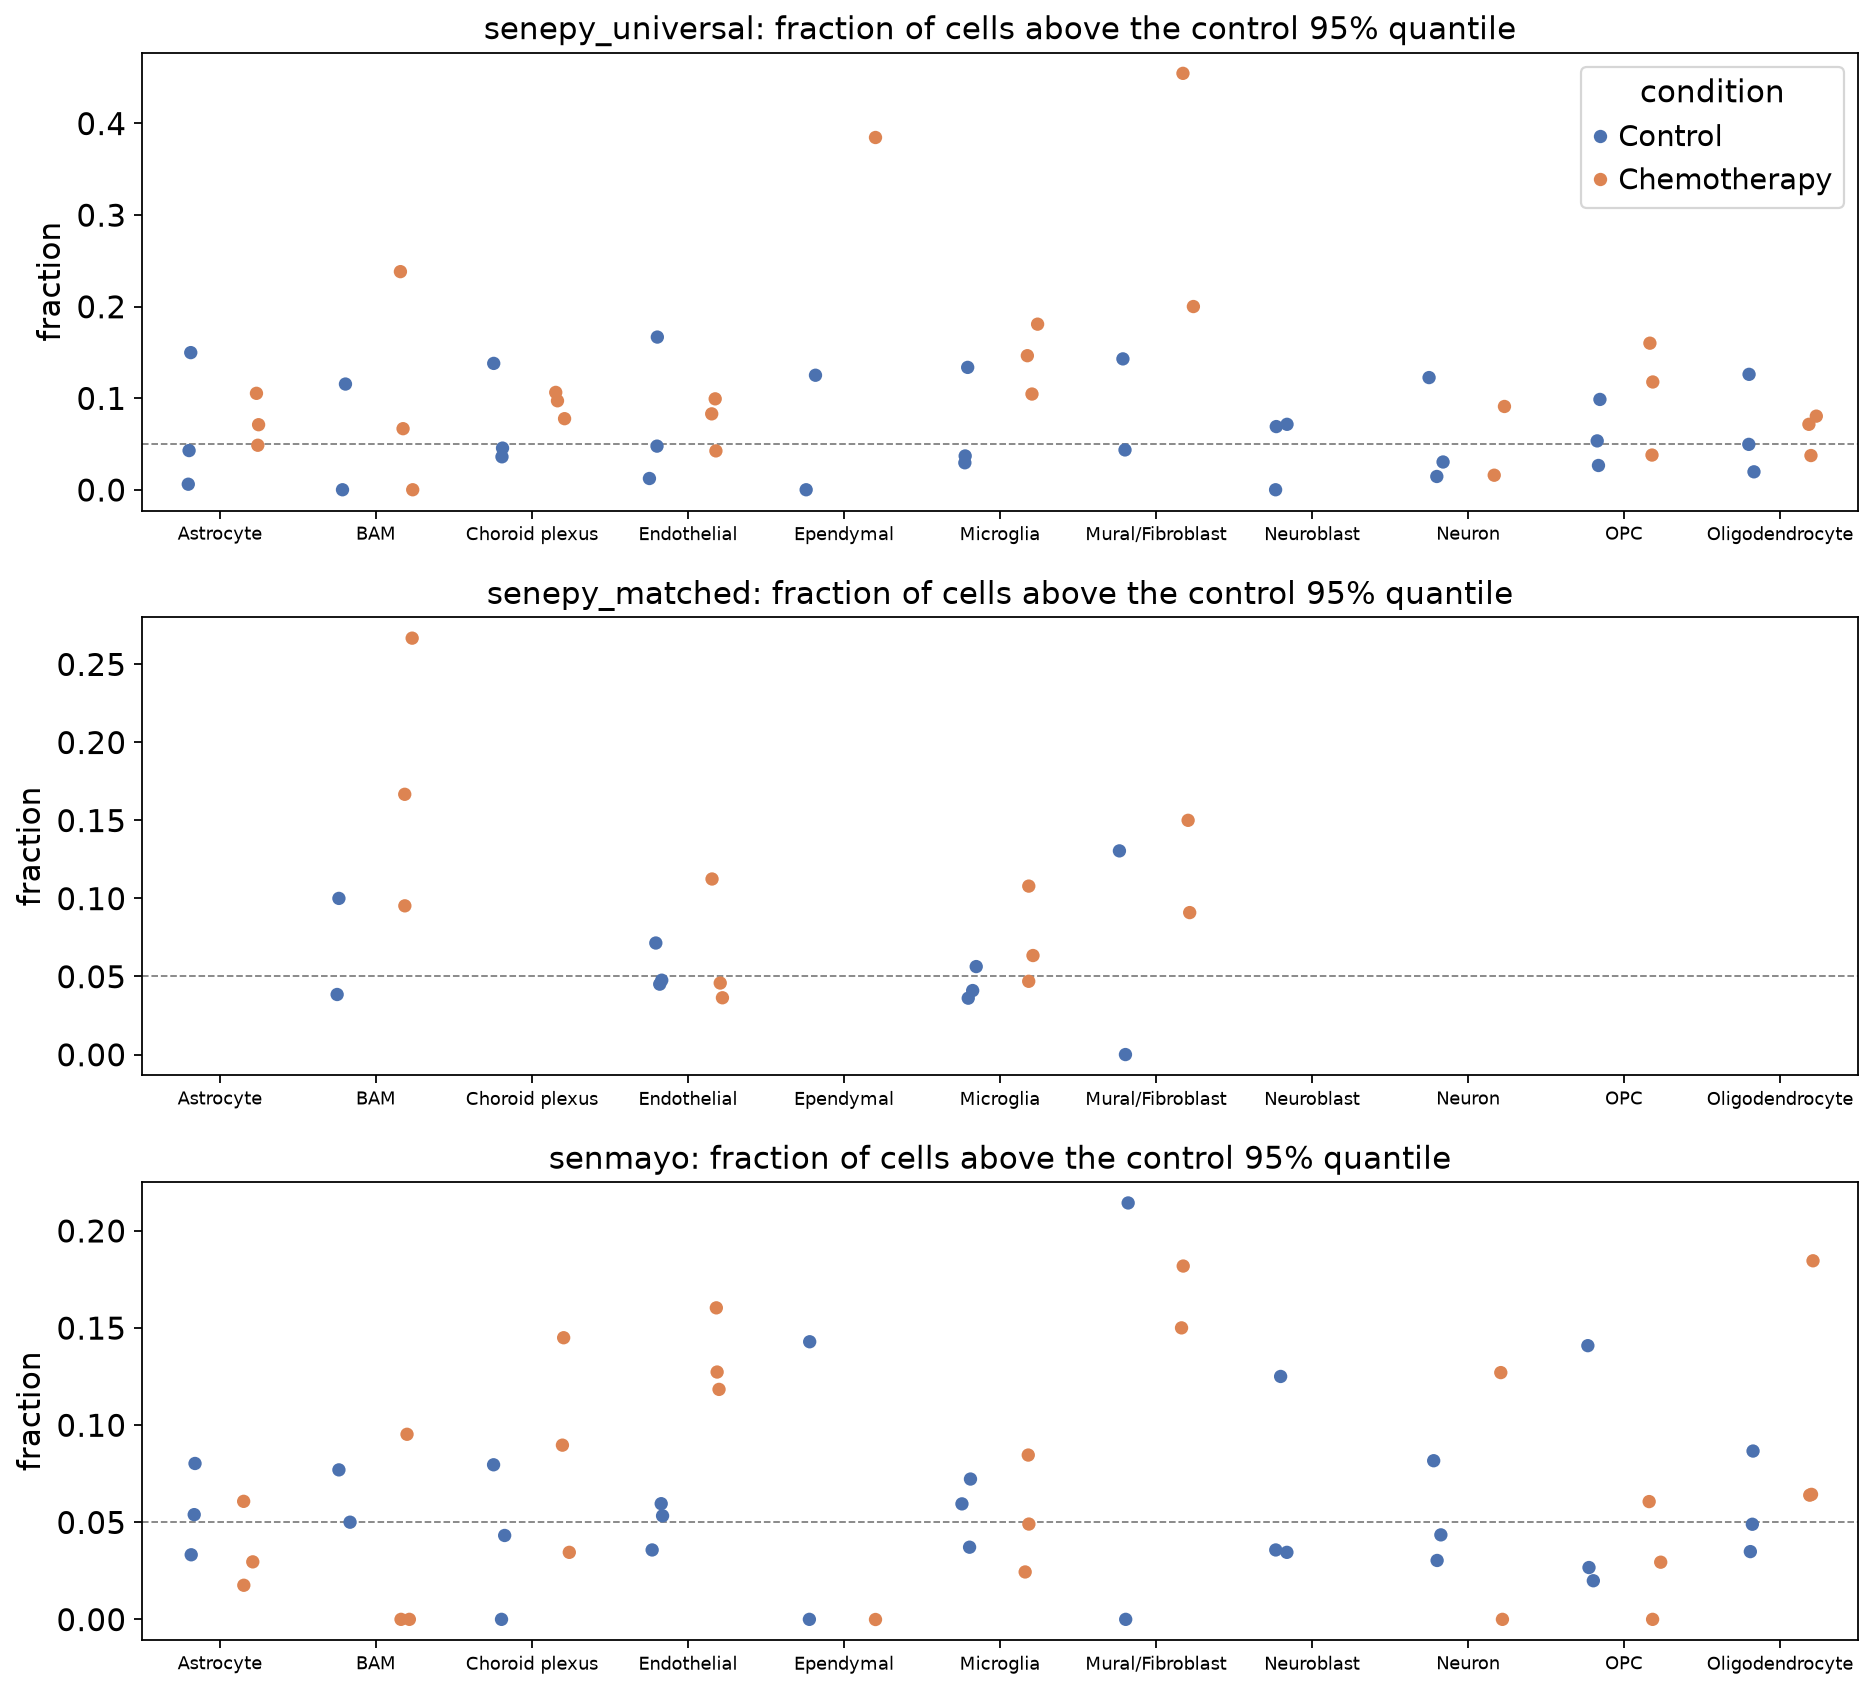

In [9]:
# Fraction of high-score cells per sample
fig, axes = plt.subplots(len(score_cols), 1, figsize=(12, 3.6 * len(score_cols)))
for ax, col in zip(axes, score_cols):
    long = (per_sample[(col, "frac_high")].stack().rename("fraction").reset_index()
            .merge(meta, left_on="biosample", right_index=True))
    sns.stripplot(long, x="cell_type", y="fraction", hue="condition", dodge=True, size=6, ax=ax,
                  palette={"Control": "#4c72b0", "Chemotherapy": "#dd8452"}, legend=ax is axes[0])
    ax.axhline(1 - p["high_quantile"], ls="--", c="0.5", lw=0.8)
    ax.set_title(f"{col}: fraction of cells above the control {p['high_quantile']:.0%} quantile")
    ax.set_xlabel(""); ax.grid(False); ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
scu.save_fig(fig, cfg, "07_frac_high_per_sample")
plt.show()

In [10]:
del adata
_ = gc.collect()